# 03 — Stochastic corruption: 10,000 bearers

Character is not the whole story: temptation comes in bursts, and so do moments of clarity. The noisy model adds a Wiener term:

$$dC = \big[\alpha u A (1 + \beta C) - \gamma W (1 - C)\big]\,dt + \sigma\, dB_t$$

It is solved with Euler–Maruyama. $C$ is reflected at 0 and absorbed at $C^*$ (the fall), and a fall inside a step is placed by linear interpolation. Bearers are simulated as vectors, in blocks that each own a child of one `SeedSequence`, so the run is reproducible for any number of worker processes.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from corruption.model import BearerParams, fate
from corruption.plotting import plot_fall_time_distribution, plot_sample_paths
from corruption.stochastic import SDEConfig, monte_carlo, sample_population, simulate_paths

FIGURES = Path("../docs/figures")
FIGURES.mkdir(parents=True, exist_ok=True)
SEED = 20261023
cfg = SDEConfig(sigma=0.02, dt=0.05, t_max=200.0)
cfg

SDEConfig(alpha=0.02, beta=3.0, gamma=0.02, c_star=0.9, sigma=0.02, u=1.0, dt=0.05, t_max=200.0)

## The population

Will, ambition and initial corruption are Beta-distributed around $\bar W = 0.6$, $\bar A = 0.75$ and $\bar C_0 = 0.05$ (concentration 20). These are invented assumptions. Deterministically, a share of these bearers would resist forever because their ambition sits below the fate boundary.

In [2]:
population = sample_population(10_000, np.random.default_rng(SEED))
deterministic_fates = pd.Series(
    [
        fate(BearerParams(W=w, A=a, c0=c, alpha=cfg.alpha, beta=cfg.beta, gamma=cfg.gamma)).value
        for w, a, c in zip(population.W, population.A, population.c0, strict=True)
    ]
).value_counts()
print("Deterministic (σ = 0) fate:", deterministic_fates.to_dict())
pd.DataFrame({"W": population.W, "A": population.A, "C0": population.c0}).describe().round(3)

Deterministic (σ = 0) fate: {'falls': 9420, 'resists': 580}


,W,A,C0
count,10000.000,10000.000,10000.000
mean,0.598,0.750,0.050
std,0.108,0.095,0.048
min,0.191,0.351,0.000
25%,0.524,0.689,0.015
50%,0.600,0.759,0.036
75%,0.674,0.820,0.071
max,0.929,0.976,0.361


## Sample paths

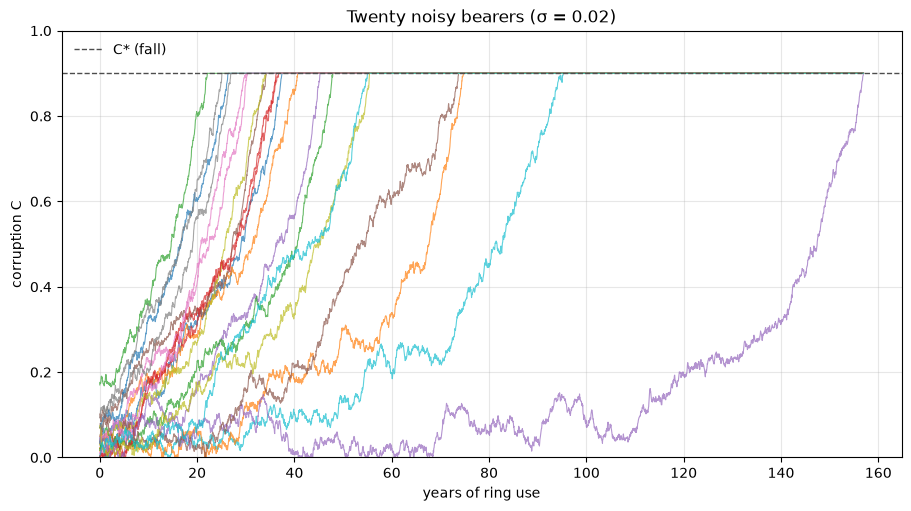

In [3]:
few = population.block(0, 20)
t, paths, _ = simulate_paths(few, cfg, np.random.default_rng(SEED))
fig = plot_sample_paths(t, paths, cfg.c_star, title="Twenty noisy bearers (σ = 0.02)")
fig.savefig(FIGURES / "sample_paths.png", dpi=150)
plt.show()

## Monte Carlo of 10,000 bearers

In [4]:
result = monte_carlo(population, cfg, seed=SEED, n_workers=2)
fell = result.fall_time[result.fell]
summary = pd.Series(
    {
        "bearers": len(result.fall_time),
        "fallen by the horizon": f"{result.fraction_fallen:.1%}",
        "mean fall time (fallen)": f"{fell.mean():.1f} y",
        "median": f"{np.median(fell):.1f} y",
        "10th percentile": f"{np.percentile(fell, 10):.1f} y",
        "90th percentile": f"{np.percentile(fell, 90):.1f} y",
    }
)
summary

bearers                     10000
fallen by the horizon       99.6%
mean fall time (fallen)    43.6 y
median                     38.4 y
10th percentile            25.8 y
90th percentile            67.0 y
dtype: object

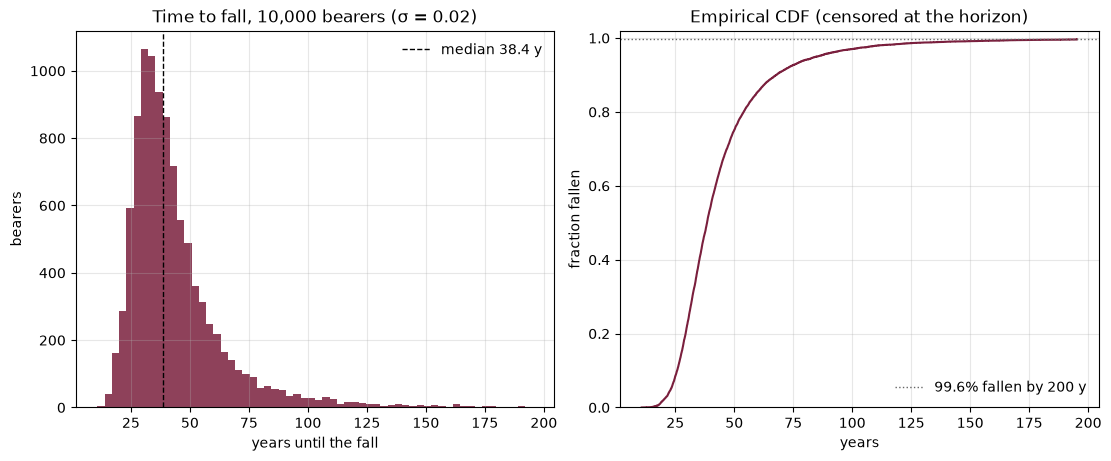

In [5]:
fig = plot_fall_time_distribution(result, title="Time to fall, 10,000 bearers (σ = 0.02)")
fig.savefig(FIGURES / "fall_time_distribution.png", dpi=150)
plt.show()

## How much does noise matter?

The same population, the same seed, different $\sigma$. With $\sigma = 0$ the result is the deterministic model. Noise does two things: it spreads fall times, and it topples bearers who would resist forever, because a run of bad luck can push them past their point of no return $C_u$, from which there is no way back.

In [6]:
rows = []
for sigma in (0.0, 0.01, 0.02, 0.05):
    r = monte_carlo(
        population, SDEConfig(sigma=sigma, dt=cfg.dt, t_max=cfg.t_max), seed=SEED, n_workers=2
    )
    f = r.fall_time[r.fell]
    rows.append(
        {
            "σ": sigma,
            "fallen": r.fraction_fallen,
            "median fall (y)": np.median(f),
            "IQR (y)": np.subtract(*np.percentile(f, [75, 25])),
        }
    )
pd.DataFrame(rows).round(3)

,σ,fallen,median fall (y),IQR (y)
0,0.00,0.942,38.952,15.286
1,0.01,0.982,39.292,17.937
2,0.02,0.996,38.410,18.901
3,0.05,1.000,32.292,19.380
